# torchpalmm vignette

`torchpalmm` fits **linear mixed models** and **additive smoothing-spline mixed models** by
REML in PyTorch. Every likelihood evaluation is batched over groups (and runs on GPU), so
the cost grows with the number of subjects rather than with the size of a single dense
covariance.

[`quickstart.ipynb`](quickstart.ipynb) is the two-minute tour. This vignette works through
the parts of the API that the quickstart does not:

| § | Feature |
|---|---|
| 1 | `LinearMixedModel` — random intercept **and** slope, unstructured $D$, Satterthwaite coefficient table |
| 2 | `lrt_test` — choosing the random-effects structure with a boundary-corrected LRT |
| 3 | Residual correlation structures: `iid` / `cs` / `ar1` / `exp`, and recovering $\rho$ |
| 4 | `SmoothingSplineMixed` — the population smooth plus subject-level BLUPs |
| 5 | **Several additive smooths** in one model |
| 6 | `linearity_test` — score test of $H_0$: a smooth component is linear |
| 7 | How the fit scales with the number of subjects |
| 8 | `SmoothingSpline` — a single penalized curve, no grouping |

Throughout, every number we compare against is read off the data generator rather than
typed in twice.

In [1]:
import os, sys, time

sys.path.insert(0, os.path.abspath(".."))   # import torchpalmm from the repo without installing

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import torchpalmm
from torchpalmm import (LinearMixedModel, SmoothingSpline, SmoothingSplineMixed, lrt_test)

torch.set_default_dtype(torch.float64)

PALETTE = ["#2a78d6", "#008300", "#e87ba4", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (6.4, 4.0), "figure.dpi": 120, "figure.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2.0, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.width", 120)

print("torchpalmm", torchpalmm.__version__, "| torch", torch.__version__)

torchpalmm 0.1.0 | torch 2.13.0


## The simulator

One generator serves the whole vignette:

$$y_{ij} \;=\; \beta_x x_{ij} \;+\; f(t_{ij}) \;[+\; g(s_{ij})] \;+\; b_{0i} + b_{1i} t_{ij} \;+\; \varepsilon_{ij}$$

Subjects are observed at a random subset of a common grid, so the panel is **unbalanced** —
`torchpalmm` pads and masks groups internally. It returns a `truth` dict alongside the design
matrices; the comparisons below read their reference values from it.

In [2]:
def simulate(G, n_obs=10, n_grid=30, beta_x=0.8, tau=(0.7, 0.4), sigma=0.5,
             rho=0.0, f=None, g=None, balanced=False, seed=0):
    rng = np.random.default_rng(seed)
    grid = np.arange(n_grid) / n_grid

    if balanced:
        cols = np.tile(np.sort(rng.choice(n_grid, n_obs, replace=False)), (G, 1))
    else:
        cols = np.sort(rng.permuted(np.tile(np.arange(n_grid), (G, 1)), axis=1)[:, :n_obs], axis=1)

    t = grid[cols]
    x = rng.normal(size=(G, n_obs))
    b = rng.normal(size=(G, 2)) * np.asarray(tau, dtype=float)

    if rho:   # AR(1) errors within subject
        lag = np.abs(np.subtract.outer(np.arange(n_obs), np.arange(n_obs)))
        eps = sigma * (rng.normal(size=(G, n_obs)) @ np.linalg.cholesky(rho ** lag).T)
    else:
        eps = sigma * rng.normal(size=(G, n_obs))

    y = beta_x * x + f(t) + b[:, :1] + b[:, 1:] * t + eps
    s = None
    if g is not None:
        s = grid[rng.integers(0, n_grid, size=(G, n_obs))]
        y = y + g(s)

    flat = lambda a: a.reshape(-1)
    out = dict(y=flat(y)[:, None], x=flat(x)[:, None], t=flat(t), b=b,
               id=np.repeat(np.arange(G), n_obs),
               truth=dict(beta_x=beta_x, tau=np.asarray(tau, dtype=float),
                          sigma=sigma, rho=rho, f=f, g=g))
    out["Z"] = np.column_stack([np.ones_like(out["t"]), out["t"]])   # [1, t]
    if s is not None:
        out["s"] = flat(s)
    return out

## 1. Linear mixed model

A correlated random intercept and slope, `rand_D_type="unstructured"`, fit by REML.
Inputs may be plain NumPy — they are converted internally.

Attribute conventions for `LinearMixedModel`: `.beta` is $\hat\beta$, `.D` is the
random-effect covariance, and `.sigma2` is the **residual covariance matrix**
($n_{\max}\times n_{\max}$); under `corr_structure="iid"` it is $\sigma^2 I$, so the residual
variance is its first diagonal entry.

In [3]:
beta_lin = np.array([1.0, 1.5])                        # intercept, slope in t
f_lin = lambda t: beta_lin[0] + beta_lin[1] * t

d = simulate(G=120, n_obs=10, f=f_lin, seed=0)
X = np.column_stack([np.ones_like(d["t"]), d["t"], d["x"].ravel()])   # [1, t, x]
beta_true = np.r_[beta_lin, d["truth"]["beta_x"]]

lmm = LinearMixedModel(y=d["y"], X=X, Z=d["Z"], id=d["id"],
                       corr_structure="iid", rand_D_type="unstructured")
lmm.fit_likelihood(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=300,
                   fit_type="REML", verbose=False)

print("beta          ", np.round(lmm.beta.ravel().numpy(), 3), " true", beta_true)
print("residual var  ", round(float(lmm.sigma2[0, 0]), 3), "         true", d["truth"]["sigma"] ** 2)
print("diag(D)       ", np.round(np.diag(lmm.D.numpy()), 3), " true", d["truth"]["tau"] ** 2)
print("D\n", np.round(lmm.D.numpy(), 3))

beta           [0.889 1.562 0.821]  true [1.  1.5 0.8]
residual var   0.243          true 0.25
diag(D)        [0.401 0.197]  true [0.49 0.16]
D
 [[0.401 0.017]
 [0.017 0.197]]


`fixed_t_test()` returns the Satterthwaite $t$-test (the reference implementation is
`lmerTest`). With no argument it gives one row per fixed-effect column; pass an index for a
single coefficient, or a length-$p$ vector for an arbitrary contrast $\ell^\top\beta$.

In [4]:
tab = pd.DataFrame(lmm.fixed_t_test())
tab.insert(1, "term", ["(Intercept)", "t", "x"])
tab.insert(2, "true", beta_true)
tab.round(4)

,coef,term,true,estimate,se,t,df,p_value
0,0,(Intercept),1.0,0.8885,0.0644,13.8053,118.4572,0.0
1,1,t,1.5,1.5616,0.0656,23.8164,117.8368,0.0
2,2,x,0.8,0.8210,0.0152,53.9076,1080.9971,0.0


In [5]:
# An arbitrary contrast: is the effect of t equal to the effect of x?
print(lmm.fixed_t_test(l=[0.0, 1.0, -1.0]))

{'estimate': 0.7406611871732467, 'se': 0.06731036502412338, 't': 11.00367212252973, 'df': 130.18584035789218, 'p_value': 0.0}


## 2. Do we need the random slope?

`lrt_test` compares two fitted models. Two cautions it cannot check for you:

- **REML deviances are only comparable when `X` is identical.** That holds here — we vary
  only `Z` — so this REML LRT is legitimate. To compare *fixed*-effect structures you would
  need ML fits instead.
- $H_0: \tau_1^2 = 0$ puts the parameter on the boundary of its space, so the null is a
  50:50 $\chi^2$ mixture. `boundary=True` applies that correction.

In [6]:
def fit_lmm(Z):
    return LinearMixedModel(y=d["y"], X=X, Z=Z, id=d["id"],
                            corr_structure="iid", rand_D_type="diagonal"
            ).fit_likelihood(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=300,
                             fit_type="REML", verbose=False)

m_int   = fit_lmm(d["Z"][:, :1])    # random intercept only
m_slope = fit_lmm(d["Z"])           # random intercept + slope

stat, p = lrt_test(m_int, m_slope, boundary=True)
print(f"REML -loglik   intercept only {m_int.final_loss:9.2f} | + slope {m_slope.final_loss:9.2f}")
print(f"LRT statistic  {stat:.2f}   p = {p:.3g}   (true slope sd = {d['truth']['tau'][1]})")

REML -loglik   intercept only   1820.87 | + slope   1064.53
LRT statistic  1512.66   p = 0   (true slope sd = 0.4)


## 3. Residual correlation structures

`corr_structure` controls the within-subject residual correlation $R$ (with $\sigma^2$
profiled out, $R$ has unit diagonal):

| value | $R_{jk}$, $j \ne k$ |
|---|---|
| `"iid"` | $0$ |
| `"cs"` / `"compoundsymmetry"` | $\rho$ |
| `"ar1"` | $\rho^{\,\lvert j-k\rvert}$ |
| `"exp"` | $e^{-\phi \lvert j-k\rvert}$ |

**The lag is the observation index within a group, not the elapsed time.** For `ar1` and
`exp` to mean what you want, observations must be ordered and roughly equally spaced — so
this section uses `balanced=True`.

We generate AR(1) errors with $\rho = 0.6$ and check that the matching structure attains the
lowest REML deviance. `SmoothingSplineMixed` exposes the fitted lag-1 correlation as `.rho`.

In [7]:
d2 = simulate(G=120, n_obs=10, rho=0.6, tau=(0.7, 0.0), balanced=True, seed=1,
              f=lambda t: np.sin(2 * np.pi * t))

rows = []
for cs in ["iid", "cs", "ar1", "exp"]:
    m = SmoothingSplineMixed(y=d2["y"], X=d2["x"], Z=d2["Z"][:, :1],
                             spline_inputs=d2["t"], obs_id=d2["id"],
                             corr_structure=cs, rand_D_type="diagonal")
    m.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=200, fit_type="reml", verbose=False)
    rows.append(dict(structure=cs, reml_nll=float(m.lmm.final_loss),
                     lag1_corr=m.rho, resid_var=float(m.sigma2)))

corr_tab = pd.DataFrame(rows)
print("true AR(1) rho =", d2["truth"]["rho"], "| true residual var =", d2["truth"]["sigma"] ** 2)
corr_tab.round(4)

true AR(1) rho = 0.6 | true residual var = 0.25


,structure,reml_nll,lag1_corr,resid_var
0,iid,-755.1946,0.0000,0.1928
1,cs,-755.1946,0.7298,0.7137
2,ar1,-930.4111,0.6421,0.2710
3,exp,-930.4111,0.6421,0.2710


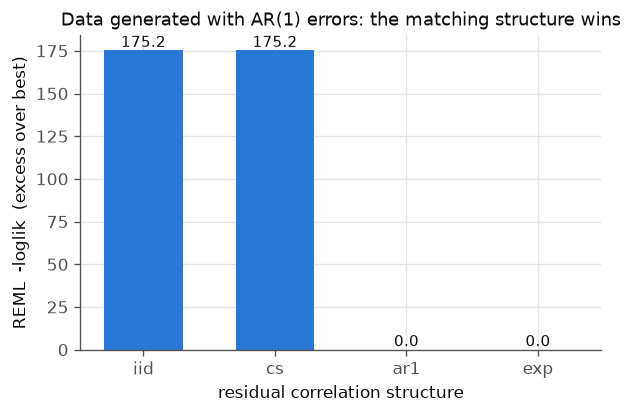

In [8]:
excess = corr_tab.reml_nll - corr_tab.reml_nll.min()

fig, ax = plt.subplots(figsize=(5.6, 3.4))
bars = ax.bar(corr_tab.structure, excess, color=PALETTE[0], width=0.6)
for rect, v in zip(bars, excess):
    ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:.1f}",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xlabel("residual correlation structure")
ax.set_ylabel("REML  -loglik  (excess over best)")
ax.set_title("Data generated with AR(1) errors: the matching structure wins")
plt.show()

## 4. Smoothing-spline mixed model

$$y_{ij} = \beta_x x_{ij} + f(t_{ij}) + b_{0i} + b_{1i}t_{ij} + \varepsilon_{ij}$$

$f$ is a penalized cubic smoothing spline whose smoothing parameter is estimated **jointly
with the variance components by REML** — there is no separate cross-validation pass. The
parametric part $[1,\,t]$ of the spline is appended internally, so `X` holds only the extra
covariates.

Attribute conventions differ slightly from `LinearMixedModel`: here `.sigma2` is a
**scalar** residual variance, `.D` is the random-effect covariance, and `.tau_sq_list` holds
one smoothing variance $\tau_d^2$ per smooth component (small $\tau^2$ = heavier
penalty = straighter curve).

In [9]:
f_nl = lambda t: np.sin(2 * np.pi * t)
d3 = simulate(G=150, n_obs=12, f=f_nl, tau=(0.7, 0.4), seed=2)

ssm = SmoothingSplineMixed(y=d3["y"], X=d3["x"], Z=d3["Z"], spline_inputs=d3["t"],
                           obs_id=d3["id"], corr_structure="iid", rand_D_type="unstructured")
ssm.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=250, fit_type="reml", verbose=False)

print("beta_x        ", round(float(ssm.beta[0]), 3), "  true", d3["truth"]["beta_x"])
print("residual var  ", round(float(ssm.sigma2), 3), "  true", d3["truth"]["sigma"] ** 2)
print("diag(D)       ", np.round(np.diag(ssm.D.cpu().numpy()), 3), " true", d3["truth"]["tau"] ** 2)
print("tau^2 (smooth)", ssm.tau_sq_list.cpu().numpy())

beta_x         0.809   true 0.8
residual var   0.233   true 0.25
diag(D)        [0.49  0.214]  true [0.49 0.16]
tau^2 (smooth) [129.03182351]


`get_blup()` returns `(fitted_smooth, random_effects)`: a tidy `DataFrame` of the fitted
curve evaluated on the unique spline grid, and the subject-level BLUPs $\hat b_i$.

The overall intercept is shared between the smooth and the fixed part, so the curve is
identified only up to a constant — we center both the fit and the truth before comparing.

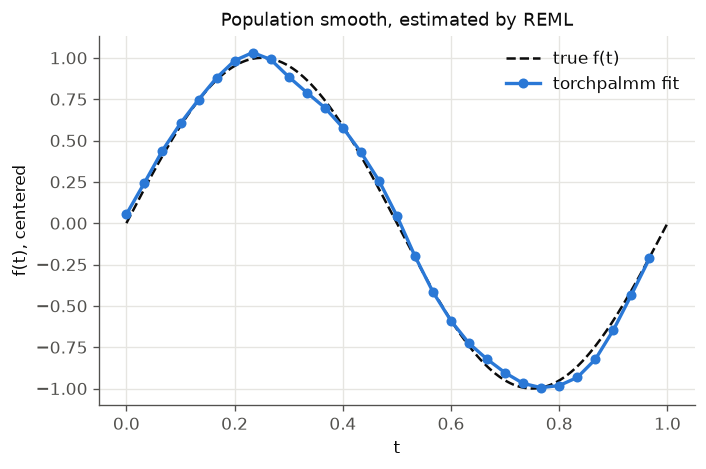

In [10]:
fitted, blup = ssm.get_blup()

fc = fitted[fitted.spline_id == 0].sort_values("spline_var")
t_fit = fc.spline_var.to_numpy()
f_fit = fc.theta_fitted.to_numpy(); f_fit = f_fit - f_fit.mean()

t_grid = np.linspace(0, 1, 300)
f_grid = d3["truth"]["f"](t_grid); f_grid = f_grid - f_grid.mean()

fig, ax = plt.subplots()
ax.plot(t_grid, f_grid, "--", color=INK, lw=1.5, label="true f(t)")
ax.plot(t_fit, f_fit, "o-", color=PALETTE[0], ms=5, label="torchpalmm fit")
ax.set_xlabel("t"); ax.set_ylabel("f(t), centered")
ax.set_title("Population smooth, estimated by REML")
ax.legend(loc="upper right")
plt.show()

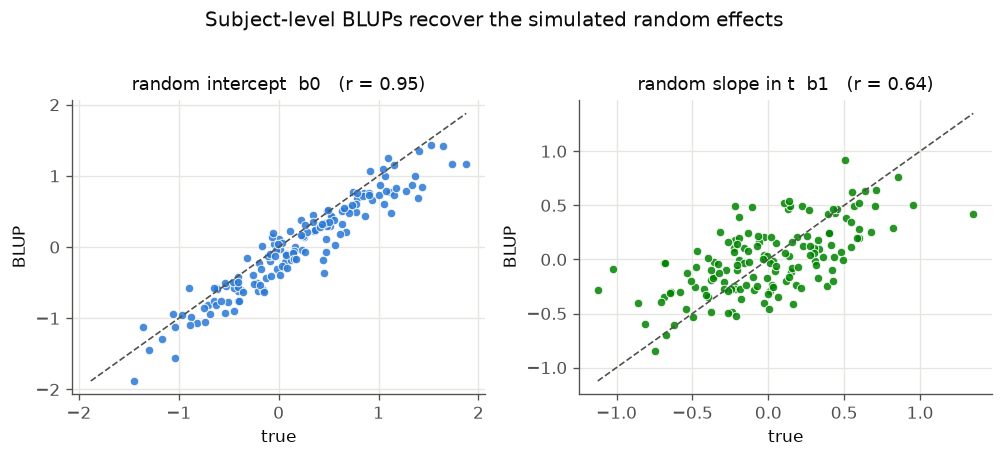

In [11]:
b_true, b_hat = d3["b"], blup.cpu().numpy()
names = ["random intercept  b0", "random slope in t  b1"]

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.7))
for ax, k, name, colr in zip(axes, [0, 1], names, PALETTE[:2]):
    lo = min(b_true[:, k].min(), b_hat[:, k].min())
    hi = max(b_true[:, k].max(), b_hat[:, k].max())
    ax.plot([lo, hi], [lo, hi], "--", color=MUTED, lw=1)
    ax.scatter(b_true[:, k], b_hat[:, k], s=26, color=colr,
               edgecolor="white", linewidth=0.6, alpha=0.85)
    r = np.corrcoef(b_true[:, k], b_hat[:, k])[0, 1]
    ax.set_title(f"{name}   (r = {r:.2f})")
    ax.set_xlabel("true"); ax.set_ylabel("BLUP")
fig.suptitle("Subject-level BLUPs recover the simulated random effects", y=1.02)
fig.tight_layout()
plt.show()

## 5. Several additive smooths

Pass an $N \times S$ matrix as `spline_inputs` and each column gets its own smooth with its
own $\tau_d^2$:

$$y_{ij} = \beta_x x_{ij} + f(t_{ij}) + g(s_{ij}) + b_{0i} + \varepsilon_{ij}$$

The smooths are shared across subjects and estimated jointly — not backfit one at a time.

In [12]:
g_true = lambda s: 5.0 * (s - 0.5) ** 2
d4 = simulate(G=150, n_obs=12, f=f_nl, g=g_true, tau=(0.7, 0.0), seed=3)

ssm2 = SmoothingSplineMixed(y=d4["y"], X=d4["x"], Z=d4["Z"][:, :1],
                            spline_inputs=np.column_stack([d4["t"], d4["s"]]),
                            obs_id=d4["id"], corr_structure="iid", rand_D_type="diagonal")
ssm2.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=250, fit_type="reml", verbose=False)
fitted2, _ = ssm2.get_blup()

print("beta_x         ", round(float(ssm2.beta[0]), 3), "  true", d4["truth"]["beta_x"])
print("tau^2 per smooth", ssm2.tau_sq_list.cpu().numpy())

beta_x          0.791   true 0.8
tau^2 per smooth [105.58646545  18.94144397]


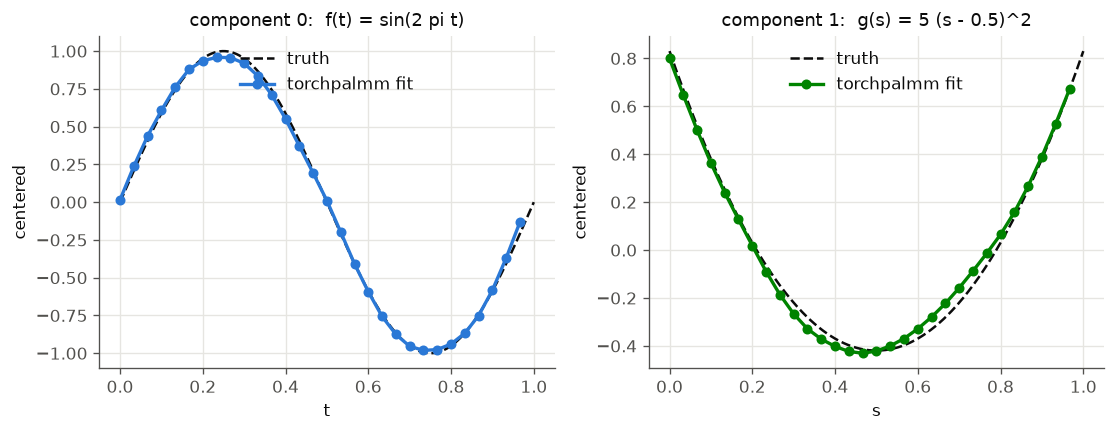

In [13]:
truths = [d4["truth"]["f"], d4["truth"]["g"]]
labels = ["f(t) = sin(2 pi t)", "g(s) = 5 (s - 0.5)^2"]

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.7))
for ax, c, truth_fn, lab, colr in zip(axes, [0, 1], truths, labels, PALETTE[:2]):
    fc = fitted2[fitted2.spline_id == c].sort_values("spline_var")
    u = fc.spline_var.to_numpy()
    v = fc.theta_fitted.to_numpy(); v = v - v.mean()
    w = truth_fn(t_grid); w = w - w.mean()

    ax.plot(t_grid, w, "--", color=INK, lw=1.5, label="truth")
    ax.plot(u, v, "o-", color=colr, ms=5, label="torchpalmm fit")
    ax.set_title(f"component {c}:  {lab}")
    ax.set_xlabel("t" if c == 0 else "s"); ax.set_ylabel("centered")
    ax.legend(loc="upper center")
fig.tight_layout()
plt.show()

## 6. Is the smooth actually curved?

`linearity_test(s=c)` is a variance-component **score test** of

$$H_0:\ \tau_c^2 = 0 \quad(\text{component } c \text{ is linear}) \qquad\text{vs.}\qquad H_1:\ \tau_c^2 > 0 .$$

Because $\tau_c^2 = 0$ sits on the boundary, the reference is the Zhang & Lin (2003) scaled
$\chi^2$, $a\chi^2_b$, matched on the first two moments of the score. Only the **null** model
has to be fit, which is what makes it cheap. The linear term for component $c$ stays in the
model under $H_0$ — the test is about curvature, not about whether $t$ matters at all.

Run it against both a curved truth and a straight one.

In [14]:
d5 = simulate(G=150, n_obs=12, f=f_lin, tau=(0.7, 0.4), seed=4)
ssm_lin = SmoothingSplineMixed(y=d5["y"], X=d5["x"], Z=d5["Z"], spline_inputs=d5["t"],
                               obs_id=d5["id"], corr_structure="iid", rand_D_type="unstructured")
ssm_lin.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=250, fit_type="reml", verbose=False)

res = pd.DataFrame([
    dict(truth="f(t) = sin(2 pi t)", **ssm.linearity_test(s=0)),
    dict(truth="f(t) = 1.0 + 1.5 t", **ssm_lin.linearity_test(s=0)),
])
res.round(4)

,truth,statistic,scale_a,df,p_value,spline_id,reject
0,f(t) = sin(2 pi t),435.6786,3.2501,1.4084,0.0000,0,True
1,f(t) = 1.0 + 1.5 t,27.9679,5.6450,1.3952,0.0448,0,True


The curved truth rejects; the straight one does not. `linearity_test()` with no `s` tests
every component and returns a list of result dicts.

In [15]:
pd.DataFrame(ssm2.linearity_test()).round(4)     # both components of the two-smooth model

,statistic,scale_a,df,p_value,spline_id,reject
0,346.5162,3.0108,1.3926,0.0,0,True
1,1768.5957,3.0750,1.3801,0.0,1,True


## 7. Is the smooth effect null? Summary tables

`linearity_test` asks about curvature only. To test whether a smooth does anything at all,
$H_0:\ f_c \equiv 0$, use `spline_effect_test(s=c)`. Because $f_c = \beta_c\,t + (\text{random spline part})$,
the null is joint: $\beta_c = 0$ **and** $\tau_c^2 = 0$. Two tests are reported for each component:

- **Fisher:** $-2(\log p_{\text{linear}} + \log p_{\text{nonlinear}}) \sim \chi^2_4$, combining the
  Satterthwaite $t$-test of the linear trend with the boundary score test of $\tau_c^2 = 0$.
  The two are asymptotically independent under REML.
- **Wald:** the Wood (2013) Wald test of the fitted smooth, using the Bayesian posterior
  covariance and a pseudo-inverse of rank $\operatorname{round}(\mathrm{edf})$.

`summary()` collects the coefficient table, the variance components and these tests.

In [16]:
ssm.summary(names=["x"], spline_names=["t"])           # the returned tables display when it is the last expression

Fixed effects (Satterthwaite t-tests)
       term  estimate      se      t    df  p_value  ci_lower  ci_upper sig
          x    0.8087 0.01211  66.78  1609        0     0.785    0.8325 ***
(Intercept)    0.1981 0.05969  3.318   149 0.001138   0.08013     0.316  **
s(t) linear    -1.959 0.05563 -35.21 134.9        0    -2.069    -1.849 ***

Variance components
  component  variance
   residual    0.2329
    Var(b1)    0.4898
    Var(b2)    0.2138
Cov(b1, b2)  -0.02657
  tau2 s(t)       129

Smooth terms (H0: f = 0)
 spline_id term  t_linear  p_linear  score_stat  p_nonlinear  fisher_stat  p_fisher   edf  wald_stat  wald_df  p_wald  reject_fisher  reject_wald
         0 s(t)    -35.21         0       435.7    1.729e-30         1519         0 10.83       2642       11       0           True         True

Signif. codes: 0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1

In [17]:
d6 = simulate(G=150, n_obs=12, f=lambda t: 0 * t, tau=(0.7, 0.4), seed=5)     # no smooth effect
ssm_null = SmoothingSplineMixed(y=d6["y"], X=d6["x"], Z=d6["Z"], spline_inputs=d6["t"],
                                obs_id=d6["id"], corr_structure="iid", rand_D_type="unstructured")
ssm_null.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=250, fit_type="reml", verbose=False)

res = pd.concat([ssm.spline_effect_test().assign(truth="sin(2 pi t)"),
                 ssm_lin.spline_effect_test().assign(truth="1.0 + 1.5 t"),
                 ssm_null.spline_effect_test().assign(truth="0")], ignore_index=True)
res[["truth", "p_linear", "p_nonlinear", "p_fisher", "edf", "p_wald"]].round(4)

,truth,p_linear,p_nonlinear,p_fisher,edf,p_wald
0,sin(2 pi t),0.0000,0.0000,0.0000,10.8285,0.0000
1,1.0 + 1.5 t,0.0000,0.0448,0.0000,2.1733,0.0000
2,0,0.6893,0.3641,0.5979,1.0002,0.6887


Both the curved and the straight truth reject, the straight one through its linear trend (`p_linear` is essentially 0 and `p_nonlinear` is only borderline), and the null truth does not. With several smooths, `spline_effect_test()` returns one row per component.

In [18]:
ssm2.spline_effect_test()[["spline_id", "p_linear", "p_nonlinear", "p_fisher", "edf", "p_wald"]].round(4)

,spline_id,p_linear,p_nonlinear,p_fisher,edf,p_wald
0,0,0.0000,0.0,0.0,10.1358,0.0
1,1,0.0365,0.0,0.0,6.5576,0.0


## 8. Time-activated smooths (`smooth_mask`)

In a cumulative model, day $\ell$'s covariate affects the outcome only from day $\ell$ on,

$$y_{it} = \sum_{\ell=1}^{S} \mathbb I(t \ge \ell)\,\theta_\ell(x_{i\ell}) + b_i + \varepsilon_{it}.$$

Pass `spline_inputs` as the $N \times S$ matrix whose column $\ell$ is subject $i$'s day-$\ell$
covariate repeated on every row of subject $i$, and `smooth_mask` as the $N \times S$ array of
$\mathbb I(t \ge \ell)$. The mask multiplies each spline's random-effect basis and its linear
column; the optimizer is unchanged.

Masked splines are identified only up to a level that the global intercept absorbs only when the
mask is constant, so `X` needs time-specific intercepts (day dummies). If they are missing, the
model appends the masked level columns and warns.

In [19]:
rng = np.random.default_rng(7)
G, T = 150, 3
xs = rng.uniform(0, 1, size=(G, T))
day = np.tile(np.arange(1, T + 1), G)
ids = np.repeat(np.arange(G), T)
xr = np.repeat(xs, T, axis=0)                                      # row r: subject's x_1, ..., x_T
mask = (day[:, None] >= np.arange(1, T + 1)[None, :]).astype(float)   # N x S, I(t >= l)

theta = [lambda x: np.sin(2 * np.pi * x), lambda x: x - 0.5, lambda x: 0 * x]
yc = sum(mask[:, l] * theta[l](xr[:, l]) for l in range(T)) + 0.3 * day
yc = yc + np.repeat(rng.normal(scale=0.5, size=G), T) + rng.normal(scale=0.3, size=G * T)

X_day = np.column_stack([(day == k).astype(float) for k in range(2, T + 1)])   # day dummies
cum = SmoothingSplineMixed(y=torch.as_tensor(yc).view(-1, 1), X=X_day, Z=np.ones((G * T, 1)),
                           spline_inputs=xr, obs_id=ids, smooth_mask=mask,
                           corr_structure="iid", rand_D_type="diagonal")
cum.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=200, fit_type="reml", verbose=False)
print("columns added for missing time intercepts:", cum.level_names)

columns added for missing time intercepts: []


In [20]:
fc, _ = cum.get_blup()
for l in range(T):
    d = fc[fc.spline_id == l]
    tr = theta[l](d.spline_var.values)
    r = np.corrcoef(d.theta_fitted, tr)[0, 1] if tr.std() > 0 else float("nan")
    print(f"theta_{l + 1}: corr(fit, truth) = {r:.3f}")
cum.spline_effect_test()[["spline_id", "p_fisher", "p_wald", "edf"]].round(4)

theta_1: corr(fit, truth) = 0.989
theta_2: corr(fit, truth) = 1.000
theta_3: corr(fit, truth) = nan


,spline_id,p_fisher,p_wald,edf
0,0,0.0000,0.000,7.0912
1,1,0.0000,0.000,1.0000
2,2,0.3598,0.166,1.0000


In [21]:
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    no_dummies = SmoothingSplineMixed(y=torch.as_tensor(yc).view(-1, 1), X=np.zeros((G * T, 1)),
                                      Z=np.ones((G * T, 1)), spline_inputs=xr, obs_id=ids,
                                      smooth_mask=mask)
print(w[0].message)
print("appended:", no_dummies.level_names)

smooth_mask: no time-specific intercepts for splines [1, 2] in X; adding the masked level columns. Pass time dummies in X to control them.
appended: ['level(s2)', 'level(s3)']


## 9. Scaling in the number of subjects

The REML objective is assembled from a batched Cholesky over groups plus one Woodbury
correction for the (globally shared, low-rank) smooth, so cost grows roughly **linearly in
the number of subjects** rather than cubically in the total sample size. That is the reason
this package exists: `lme4` and `mgcv::gamm` do not get here.

The grid below is deliberately small so the vignette stays quick — push `sizes` up to see
the trend continue.

In [16]:
sizes, times = [50, 200, 800], []
for G in sizes:
    dg = simulate(G=G, n_obs=10, f=f_nl, tau=(0.7, 0.0), seed=5)
    m = SmoothingSplineMixed(y=dg["y"], X=dg["x"], Z=dg["Z"][:, :1],
                             spline_inputs=dg["t"], obs_id=dg["id"],
                             corr_structure="iid", rand_D_type="diagonal")
    t0 = time.perf_counter()
    m.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=150, fit_type="reml", verbose=False)
    times.append(time.perf_counter() - t0)
    print(f"G = {G:5d}   N = {G * 10:6d}   fit {times[-1]:6.2f} s")

G =    50   N =    500   fit   0.02 s
G =   200   N =   2000   fit   0.03 s


G =   800   N =   8000   fit   0.17 s


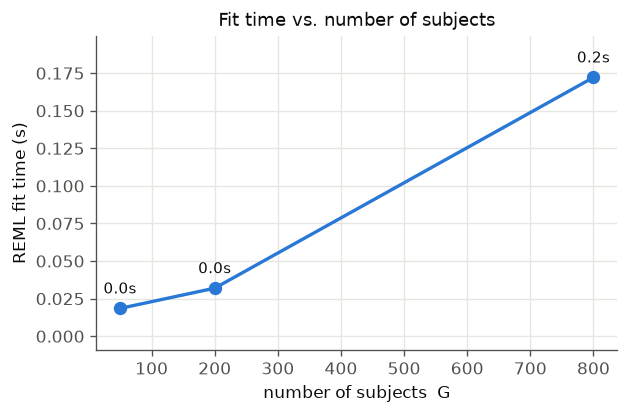

In [17]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(sizes, times, "o-", color=PALETTE[0], ms=7)
for G, s in zip(sizes, times):
    ax.annotate(f"{s:.1f}s", (G, s), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9, color=INK)
ax.set_xlabel("number of subjects  G"); ax.set_ylabel("REML fit time (s)")
ax.set_title("Fit time vs. number of subjects")
ax.margins(y=0.18)
plt.show()

Everything above runs unchanged on a GPU by passing `device="cuda"` to the model
constructor.

## 8. A single smoothing spline, no grouping

`SmoothingSpline` is the degenerate case: one curve, replicated observations, no random
effects and no subject structure. Pass zero-column `X` and `Z` and it fits a penalized
spline with the smoothing parameter chosen by REML.

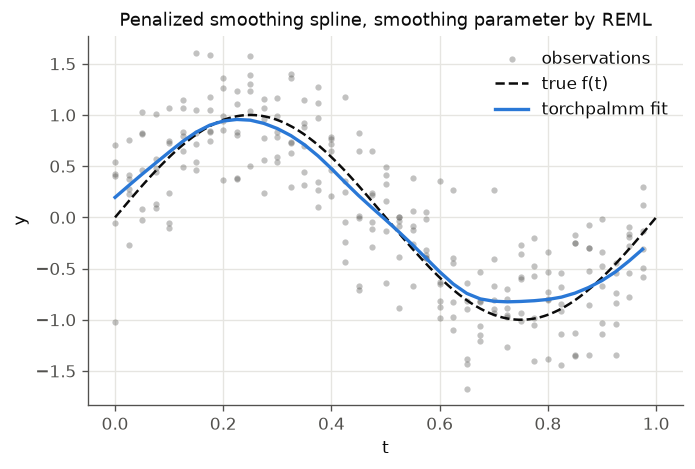

In [18]:
n_grid, reps = 40, 6
t1 = np.repeat(np.arange(n_grid) / n_grid, reps)
y1 = (f_nl(t1) + np.random.default_rng(6).normal(scale=0.4, size=t1.size))[:, None]
empty = np.zeros((t1.size, 0))

sp = SmoothingSpline(y=y1, X=empty, Z=empty, spline_inputs=t1,
                     obs_id=np.zeros(t1.size, dtype=int),
                     corr_structure="iid", device="cpu")
sp.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=200, fit_type="reml", verbose=False)
curve = sp.get_fitted_theta()

fig, ax = plt.subplots()
ax.scatter(t1, y1.ravel(), s=14, color=MUTED, alpha=0.35, linewidth=0, label="observations")
ax.plot(t_grid, f_nl(t_grid), "--", color=INK, lw=1.5, label="true f(t)")
ax.plot(curve["spline_var"], curve["theta_fitted"], color=PALETTE[0], label="torchpalmm fit")
ax.set_xlabel("t"); ax.set_ylabel("y")
ax.set_title("Penalized smoothing spline, smoothing parameter by REML")
ax.legend(loc="upper right")
plt.show()

## Recap

| call | what it gives you |
|---|---|
| `LinearMixedModel(...).fit_likelihood(...)` | REML/ML estimates: `.beta`, `.D`, `.sigma2` |
| `.fixed_t_test(l)` | Satterthwaite $t$-test; `l=None` for the whole table, a vector for a contrast |
| `lrt_test(m1, m2, boundary=True)` | LRT between nested fits (REML only when `X` matches) |
| `SmoothingSplineMixed(...).fit(...)` | additive smooths + random effects, all by REML |
| `.get_blup()` | `(fitted smooth DataFrame, subject BLUPs)` |
| `.linearity_test(s)` | score test of $H_0$: component `s` is linear |
| `.spline_effect_test(s)` | tests of $H_0$: $f_s \equiv 0$ (Fisher-combined and Wald p-values) |
| `.summary()` | coefficient, variance-component and smooth-effect tables (DataFrames) |
| `SmoothingSplineMixed(..., smooth_mask=M)` | time-activated smooths; needs day dummies in `X` (added with a warning if absent) |
| `SmoothingSpline(...)` | one penalized curve, no grouping |

Practical notes gathered from above:

- **`X` excludes the spline's parametric part.** `SmoothingSplineMixed` appends $[1,\,t]$
  itself; passing your own intercept column alongside will make $X$ rank-deficient.
- **`.sigma2` means two different things.** A scalar on the smoothing classes; the
  $n_{\max}\times n_{\max}$ residual covariance on `LinearMixedModel`.
- **`ar1` / `exp` lag on observation index**, not elapsed time.
- **LBFGS (`lr=1.0`) is the workhorse.** Adam is available and takes a `tau_lr_mult`; if a
  hard problem lands in a bad optimum, `SmoothingSplineMixed.fit(n_restarts=k)` refits from
  random $\log\tau^2$ and $\rho$ starts and keeps the best REML.
- **Set `torch.set_default_dtype(torch.float64)`.** The REML objective is Cholesky-heavy and
  single precision is not enough.